# Оценка достоверности выполнения задач LLM-агентами по структуре траектории

Демонстрация к магистерской работе «Разработка модели оценки достоверности выполнения задач LLM-агентами
на основе анализа структуры траекторий выполнения».

**Достоверное выполнение** — агент отправил результат (submit), и скрытые тесты SWE-bench подтверждают, что задача
решена. Модель по ходу работы агента (шагам, командам, их фазам) оценивает **риск**: вероятность, что отправленный
результат тесты не пройдёт.

Запуск: *Runtime → Run all* на чистом рантайме, около 2–3 минут. Ключи API, вызовы LLM и Docker не нужны;
все случайные операции — с `seed = 42`.

## 1. Установка и загрузка

Ставится одна библиотека с закреплённой версией (scikit-learn — от неё зависят числа логистической регрессии);
numpy, pandas, pyarrow, scipy и matplotlib берутся из рантайма Colab, их версии печатаются ниже. Данные скачиваются
из релиза репозитория по прямым ссылкам, SHA256 каждого файла сверяется с ожидаемым.

In [1]:
%pip install -q scikit-learn==1.9.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib, json, os, sys, time, urllib.error, urllib.request, zipfile
from pathlib import Path

T0 = time.time()
SEED = 42
REPO = "Kiruha667/diss"
TAG = "demo-data-v1"
# Files of the GitHub release TAG; DEMO_BASE_URL overrides the location (used for the local test run).
BASE_URL = os.environ.get("DEMO_BASE_URL", f"https://github.com/{REPO}/releases/download/{TAG}")
EXPECTED_SHA256 = {
    "runs.parquet": "7b5aa9e487d6f397ec99ab1609557373621e0b639e844556b917d575339d785c",
    "steps.parquet": "8d3f125e97223b408dd84780355c4ab6e36c6b04d74159f58fe2f61d7a517b90",
    "examples.json": "c8c906f8574d9a86e6ddf190b41ab59a924137d4b818462fbff4d16181efa372",
    "demo_lib.zip": "b122a22f9d5d864e7530bf7593fcc38b1905501046f1916eb2bc68f583f97004"
}
DATA = Path("demo_data")
DATA.mkdir(exist_ok=True)


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def download(url, path, attempts=3):
    # streamed download with a timeout and retries (transient network errors)
    for i in range(attempts):
        try:
            with urllib.request.urlopen(url, timeout=120) as r, open(path, "wb") as fh:
                while chunk := r.read(1 << 20):
                    fh.write(chunk)
            return
        except urllib.error.HTTPError as e:
            raise RuntimeError(f"cannot download {url} (HTTP {e.code}): the release must be public") from None
        except OSError as e:
            if i == attempts - 1:
                raise
            print(f"retry {i + 1} for {url}: {e}")
            time.sleep(3)


for name, expected in EXPECTED_SHA256.items():
    path = DATA / name
    if not path.exists() or sha256(path) != expected:
        download(f"{BASE_URL}/{name}", path)
    got = sha256(path)
    assert got == expected, f"SHA256 mismatch for {name}: {got}"
    print(f"{name:14s} {path.stat().st_size / 1e6:7.1f} MB   SHA256 OK")

with zipfile.ZipFile(DATA / "demo_lib.zip") as z:
    z.extractall(DATA)
sys.path.insert(0, str(DATA.resolve()))

runs.parquet       1.6 MB   SHA256 OK


steps.parquet     66.8 MB   SHA256 OK
examples.json      0.0 MB   SHA256 OK
demo_lib.zip       0.0 MB   SHA256 OK


In [3]:
import math
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import pyarrow.parquet as pq
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from demo_lib.features import FEATURES, LEN, PHASE_CODES, step_phases, steps_from_frame, trajectory_features

np.random.seed(SEED)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| pyarrow",
      pyarrow.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib",
      matplotlib.__version__)

runs = pd.read_parquet(DATA / "runs.parquet")
examples = json.loads((DATA / "examples.json").read_text(encoding="utf-8"))
steps_file = pq.ParquetFile(DATA / "steps.parquet")
# Only the steps of the example runs are needed below; read them with a filter instead of all rows.
example_ids = [e["run_id"] for e in examples]
steps = pq.read_table(DATA / "steps.parquet", filters=[("run_id", "in", example_ids)]).to_pandas()
print("runs.parquet:", runs.shape, "| steps.parquet:", steps_file.metadata.num_rows, "rows,",
      steps_file.metadata.num_columns, "columns | steps of the examples:", len(steps))

python 3.12.14 | numpy 2.5.4 | pandas 3.0.6 | pyarrow 26.0.0 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


runs.parquet: (7975, 33) | steps.parquet: 465630 rows, 11 columns | steps of the examples: 159


## 2. Обзор датасета

Одна строка `runs` — один прогон агента mini-SWE-agent на одной задаче SWE-bench Verified. `resolved` — прошли ли
скрытые тесты; признаки модели (последние колонки) посчитаны кодом пайплайна по всей траектории.

In [4]:
print("runs.shape =", runs.shape)
display(runs.dtypes.to_frame("dtype").T)
display(runs.head())

runs.shape = (7975, 33)


,run_id,task_id,repo,model,model_family,agent_version,n_steps,exit_status,submitted,claim_success,...,phase_bigram_entropy,share_before_first_edit,repeat_ratio,distinct_cmd_ratio,nonzero_rc_share,n_files_edited,n_file_switches,seg_len_steps,seg_len_sent,n_edits
dtype,str,str,str,str,str,str,int64,str,int64,int64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


,run_id,task_id,repo,model,model_family,agent_version,n_steps,exit_status,submitted,claim_success,...,phase_bigram_entropy,share_before_first_edit,repeat_ratio,distinct_cmd_ratio,nonzero_rc_share,n_files_edited,n_file_switches,seg_len_steps,seg_len_sent,n_edits
0,20250726_mini-v1.0.0_gemini-2.5-pro/astropy__astropy-12907,astropy__astropy-12907,astropy/astropy,gemini-2.5-pro,google,1.0.0,5,Submitted,1,1,...,0.630930,0.200000,0.0,1.000000,0.000000,2.0,1.0,2.0,10.0,2.0
1,20250726_mini-v1.0.0_gemini-2.5-pro/astropy__astropy-13033,astropy__astropy-13033,astropy/astropy,gemini-2.5-pro,google,1.0.0,13,Submitted,1,1,...,0.509162,0.307692,0.0,0.923077,0.000000,3.0,2.0,3.0,30.0,3.0
2,20250726_mini-v1.0.0_gemini-2.5-pro/astropy__astropy-13236,astropy__astropy-13236,astropy/astropy,gemini-2.5-pro,google,1.0.0,13,Submitted,1,0,...,0.257637,0.769231,0.0,0.846154,0.100000,1.0,0.0,2.0,12.0,1.0
3,20250726_mini-v1.0.0_gemini-2.5-pro/astropy__astropy-13398,astropy__astropy-13398,astropy/astropy,gemini-2.5-pro,google,1.0.0,12,Submitted,1,0,...,0.668179,0.000000,0.0,0.750000,0.272727,3.0,3.0,2.0,16.0,5.0
4,20250726_mini-v1.0.0_gemini-2.5-pro/astropy__astropy-13453,astropy__astropy-13453,astropy/astropy,gemini-2.5-pro,google,1.0.0,39,Submitted,1,0,...,0.480868,0.153846,0.0,0.666667,0.142857,3.0,7.0,2.0,10.0,10.0


In [5]:
both = runs.groupby("task_id").resolved.nunique().eq(2)
print(f"resolved share: {runs.resolved.mean():.3f}   tasks: {runs.task_id.nunique()}   "
      f"models: {runs.model.nunique()}   families: {runs.model_family.nunique()}   "
      f"agent versions: {runs.agent_version.nunique()}")
print(f"tasks with both resolved and unresolved runs: {int(both.sum())}")
by_model = (runs.groupby(["model", "model_family", "agent_version"])
            .agg(runs=("run_id", "size"), resolved_share=("resolved", "mean"))
            .round(3).sort_values("runs", ascending=False))
display(by_model)
display(runs.exit_status.value_counts().to_frame("runs"))

resolved share: 0.660   tasks: 500   models: 16   families: 7   agent versions: 8
tasks with both resolved and unresolved runs: 337


,,,runs,resolved_share
model,model_family,agent_version,,
claude-haiku-4-5-20251001@high,anthropic,2.0.0,500,0.670
deepseek-v3.2@high,deepseek,2.0.0,500,0.700
devstral-2512,mistral,1.17.2,500,0.538
devstral-small-2512,mistral,1.17.2,500,0.564
gemini-3-pro-preview,google,1.15.0,500,0.742
glm-5@high,zhipu,2.0.0,500,0.728
kimi-k2.5@high,moonshot,2.0.0,500,0.708
minimax-m2.5@high,minimax,2.0.0,500,0.758
claude-sonnet-4-5-20250929,anthropic,1.13.3,499,0.707


,runs
exit_status,
Submitted,7864
LimitsExceeded,108
RetryError,3


## 3. Популяция

Оценивается только то, что агент **отправил**: `submitted == 1` (статус выхода `Submitted`). Прогоны, оборвавшиеся
по лимиту или ошибке, результата не сдали — оценивать там нечего, поэтому они исключены. Все дальнейшие расчёты — на
этой популяции. Целевая переменная — `1 − resolved` (задача не решена), риск модели — её вероятность.

In [6]:
pop = runs[runs.submitted == 1].sort_values("run_id").reset_index(drop=True)
excluded = runs[runs.submitted == 0]
print(f"population (submitted == 1): {len(pop)} runs, {pop.task_id.nunique()} tasks; excluded: {len(excluded)}")
display(excluded.exit_status.value_counts().to_frame("excluded runs"))
y = (1 - pop.resolved).to_numpy()
print(f"unresolved share in the population: {y.mean():.3f}")

population (submitted == 1): 7864 runs, 500 tasks; excluded: 111


,excluded runs
exit_status,
LimitsExceeded,108
RetryError,3


unresolved share in the population: 0.330


## 4. Примеры траекторий

Каждый шаг агента размечен одной из трёх фаз — разметка существующего кода (правила G0/E5 над выполненными
bash-командами). Коды в `phase_seq`:

| код | фаза | что это |
|---|---|---|
| `E` | edit | шаг правит код: `sed -i`, запись в файл через `>`/heredoc/`tee`, `git apply`, `patch`, запись из python |
| `V` | verify | шаг запускает проверку: pytest / tox / `python -m unittest`, скрипт тестов, python-код с `assert` |
| `O` | other | всё остальное: чтение файлов, поиск, запуск без проверки, служебные команды |

Если в шаге есть и правка, и проверка, побеждает правка. Примеры отобраны детерминированно (seed 42), предпочтительно
длиной 15–40 шагов.

In [7]:
LEGEND = {"E": "edit", "V": "verify", "O": "other"}
TYPE_NAMES = {"pair_resolved": "пара внутри задачи: решено", "pair_unresolved": "пара внутри задачи: не решено",
              "false_claim": "ложное заявление об успехе", "verified_success": "достоверное выполнение с проверкой",
              "not_submitted": "обрыв без отправки"}
runs_by_id = runs.set_index("run_id")


def show_meta(run_id):
    r = runs_by_id.loc[run_id]
    return pd.DataFrame([{"task_id": r.task_id, "model": r.model, "agent_version": r.agent_version,
                          "n_steps": r.n_steps, "exit_status": r.exit_status, "submitted": r.submitted,
                          "claim_success": r.claim_success, "resolved": r.resolved}], index=[run_id])


def show_steps(run_id):
    s = steps[steps.run_id == run_id].sort_values("step_idx")
    return pd.DataFrame({"step_idx": s.step_idx, "phase": s.phase, "command": s.command,
                         "output (150)": s.output.str.slice(0, 150)}).set_index("step_idx")


def show_example(e):
    display(Markdown(f"### {TYPE_NAMES[e['type']]}\n`{e['run_id']}`"))
    display(show_meta(e["run_id"]))
    print("phase_seq:", runs_by_id.loc[e["run_id"], "phase_seq"])
    display(show_steps(e["run_id"]))
    print("final_message:", runs_by_id.loc[e["run_id"], "final_message"] or "<no final message>")


pair = [e for e in examples if e["type"].startswith("pair_")]
display(Markdown(f"### Пара внутри одной задачи `{pair[0]['task_id']}`: две последовательности фаз"))
for e in pair:
    r = runs_by_id.loc[e["run_id"]]
    print(f"{TYPE_NAMES[e['type']]:30s} {r.model:28s} resolved={r.resolved}  {r.phase_seq}")

### Пара внутри одной задачи `django__django-11333`: две последовательности фаз

пара внутри задачи: решено     kimi-k2.5@high               resolved=1  O O O O E O O O O O E O E O O E O O O E E O O O E E O V O E O E O O O V O O O
пара внутри задачи: не решено  GLM-4.5                      resolved=0  O O O O O O O O E O E O E O O O E O E E E O O O E E O


In [8]:
for e in pair:
    show_example(e)

### пара внутри задачи: решено
`20260217_mini-v2.0.0_kimi-k2-5-high/django__django-11333`

,task_id,model,agent_version,n_steps,exit_status,submitted,claim_success,resolved
20260217_mini-v2.0.0_kimi-k2-5-high/django__django-11333,django__django-11333,kimi-k2.5@high,2.0.0,39,Submitted,1,0,1


phase_seq: O O O O E O O O O O E O E O O E O O O E E O O O E E O V O E O E O O O V O O O


,phase,command,output (150)
step_idx,,,
0,other,"find . -type f -name ""*.py"" | xargs grep -l ""get_resolver"" | head -20",./tests/view_tests/views.py\n./tests/urlpatterns_reverse/tests.py\n./django/urls/__init__.py\n./django/urls/resolvers.py\n./django/urls/base.py\n./django/c
1,other,cat ./django/urls/resolvers.py,The output of your last command was too long.\nPlease try a different command that produces less output.\nIf you're looking at a file you can try use he
2,other,cat ./django/urls/base.py,"from urllib.parse import urlsplit, urlunsplit\n\nfrom asgiref.local import Local\n\nfrom django.utils.encoding import iri_to_uri\nfrom django.utils.functio"
3,other,"grep -n ""get_ns_resolver"" ./django/urls/resolvers.py | head -20","74:def get_ns_resolver(ns_pattern, resolver, converters):"
4,edit,"cat > test_issue.py << 'EOF'\n#!/usr/bin/env python\n""""""\nTest script to verify the issue: multiple URLResolvers are created\nwhen get_resolver is called wi...","Traceback (most recent call last):\n File ""/testbed/test_issue.py"", line 13, in <module>\n django.setup()\n File ""/testbed/django/__init__.py"", line"
5,other,pip install asgiref,Collecting asgiref\n Downloading asgiref-3.11.1-py3-none-any.whl.metadata (9.3 kB)\nDownloading asgiref-3.11.1-py3-none-any.whl (24 kB)\nInstalling coll
6,other,python test_issue.py,"Traceback (most recent call last):\n File ""/testbed/test_issue.py"", line 13, in <module>\n django.setup()\n File ""/testbed/django/__init__.py"", line"
7,other,pip install pytz,Collecting pytz\n Downloading pytz-2025.2-py2.py3-none-any.whl.metadata (22 kB)\nDownloading pytz-2025.2-py2.py3-none-any.whl (509 kB)\nInstalling colle
8,other,python test_issue.py,"Traceback (most recent call last):\n File ""/testbed/test_issue.py"", line 13, in <module>\n django.setup()\n File ""/testbed/django/__init__.py"", line"


final_message: The patch looks correct. Let me verify there are no unintended changes and only our fix is present: The patch is complete. Let me submit the final output:


### пара внутри задачи: не решено
`20250822_mini-v1.9.1_glm-4.5/django__django-11333`

,task_id,model,agent_version,n_steps,exit_status,submitted,claim_success,resolved
20250822_mini-v1.9.1_glm-4.5/django__django-11333,django__django-11333,GLM-4.5,1.9.1,27,Submitted,1,0,0


phase_seq: O O O O O O O O E O E O E O O O E O E E E O O O E E O


,phase,command,output (150)
step_idx,,,
0,other,ls -la,total 172\ndrwxrwxrwx 1 root root 4096 Oct 24 2024 .\ndrwxr-xr-x 1 root root 4096 Aug 22 21:35 ..\n-rw-r--r-- 1 root root 782 Oct 24 2024 .ed
1,other,ls -la django/,total 92\ndrwxrwxrwx 19 root root 4096 Oct 24 2024 .\ndrwxrwxrwx 1 root root 4096 Oct 24 2024 ..\n-rw-r--r-- 1 root root 799 Oct 24 2024 __init__.p
2,other,ls -la django/urls/,total 64\ndrwxrwxrwx 2 root root 4096 Oct 24 2024 .\ndrwxrwxrwx 19 root root 4096 Oct 24 2024 ..\n-rw-r--r-- 1 root root 959 Oct 24 2024 __init_
3,other,cat django/urls/resolvers.py,The output of your last command was too long.\nPlease try a different command that produces less output.\nIf you're looking at a file you can try use he
4,other,"sed -n '40,50p' django/urls/resolvers.py",# in an empty value.\n self.app_names = [x for x in app_names if x] if app_names else []\n self.app_name = ':'.join(self.app_names
5,other,"grep -n ""def get_resolver"" django/urls/resolvers.py",67:def get_resolver(urlconf=None):
6,other,"sed -n '65,75p' django/urls/resolvers.py",@functools.lru_cache(maxsize=None)\ndef get_resolver(urlconf=None):\n if urlconf is None:\n urlconf = settings.ROOT_URLCONF\n return URLResol
7,other,cat django/urls/base.py,"from urllib.parse import urlsplit, urlunsplit\n\nfrom asgiref.local import Local\n\nfrom django.utils.encoding import iri_to_uri\nfrom django.utils.functio"
8,edit,"sed -i '67,71c\\n@functools.lru_cache(maxsize=None)\\ndef get_resolver(urlconf=None):\\n if urlconf is None:\\n urlconf = settings.ROOT_URLCONF\\n...",


final_message: Excellent! The verification script confirms that the fix has been implemented correctly. Let me now run a final check to see the actual changes that were made to the file by using git diff to show what we've modified. [Response interrupted by a tool use result. Only one tool may be used at a time and should be placed at the end of the message.]


In [9]:
for e in examples:
    if not e["type"].startswith("pair_"):
        show_example(e)

### ложное заявление об успехе
`20251124_mini-v1.17.0_minimax-m2/psf__requests-1766`

,task_id,model,agent_version,n_steps,exit_status,submitted,claim_success,resolved
20251124_mini-v1.17.0_minimax-m2/psf__requests-1766,psf__requests-1766,minimax-m2,1.17.0,38,Submitted,1,1,0


phase_seq: O O O O O O O O E O E E E O O E O V O O O O O V E V E O O E O E O O O E O O


,phase,command,output (150)
step_idx,,,
0,other,"find /testbed -type f -name ""*.py"" | head -20",/testbed/setup.py\n/testbed/test_requests.py\n/testbed/build/lib/requests/exceptions.py\n/testbed/build/lib/requests/api.py\n/testbed/build/lib/requests/a
1,other,"find /testbed -type f -name ""*.py"" -not -path ""*/build/*"" | grep -E ""(auth|digest)"" | head -10",/testbed/requests/auth.py
2,other,cat /testbed/requests/auth.py,"# -*- coding: utf-8 -*-\n\n""""""\nrequests.auth\n~~~~~~~~~~~~~\n\nThis module contains the authentication handlers for Requests.\n""""""\n\nimport os\nimport re\..."
3,other,"grep -r ""qop"" /testbed/test_requests.py | head -20",
4,other,"grep -n -i ""digest"" /testbed/test_requests.py | head -20","14:from requests.auth import HTTPDigestAuth\n264: def test_DIGEST_HTTP_200_OK_GET(self):\n266: auth = HTTPDigestAuth('user', 'pass')\n267:"
5,other,"sed -n '264,320p' /testbed/test_requests.py","def test_DIGEST_HTTP_200_OK_GET(self):\n\n auth = HTTPDigestAuth('user', 'pass')\n url = httpbin('digest-auth', 'auth', 'user', 'pass')"
6,other,"sed -n '125,135p' /testbed/requests/auth.py","HA1 = hash_utf8('%s:%s:%s' % (HA1, nonce, cnonce))\n\n if qop is None:\n respdig = KD(HA1, ""%s:%s"" % (nonce, HA2))\n"
7,other,"sed -n '135,145p' /testbed/requests/auth.py","self.last_nonce = nonce\n\n # XXX should the partial digests be encoded too?\n base = 'username=""%s"", realm=""%s"", nonce=""%s"", uri="""
8,edit,"cat > /testbed/test_qop_quotes.py << 'EOF'\n#!/usr/bin/env python\n# -*- coding: utf-8 -*-\n""""""Test script to verify qop-options quoting in Digest Auth""""""\n...",


final_message: Perfect! The fix is working correctly. Let me now summarize what I've accomplished: ## Summary of Changes 1. **Identified the Issue**: The `HTTPDigestAuth` class in `/testbed/requests/auth.py` was generating Digest Auth headers with unquoted `qop` values, violating RFC2617. 2. **Located the Problem**: Found the issue on line 145 (originally line 144 before the fix) where `qop=auth` was being added without quotes. 3. **Applied the Fix**: Changed `qop=auth` to `qop="auth"` in the format string. 4. **Verified the Fix**: Created comprehensive tests to ensure: - The fix works for standard `qop=auth` scenarios - The fix works for multiple qop options - The fix doesn't break cases where qop is None or empty - The implementation is RFC2617 compliant - The implementation matches curl's behavior The change was minimal and surgical - just adding quotes around the `auth` value in the qop directive. This makes the implementation compliant with RFC2617 and compatible with servers that

...

### обрыв без отправки
`20260226_mini-v2.0.0_gemini-3-pro-high/django__django-14011`

,task_id,model,agent_version,n_steps,exit_status,submitted,claim_success,resolved
20260226_mini-v2.0.0_gemini-3-pro-high/django__django-14011,django__django-14011,gemini-3-pro-preview@high,2.0.0,40,LimitsExceeded,0,0,0


phase_seq: O O O O O O O O E O O O O E O O O O O O O O O O E O E O E O E E O O O E O O O O


,phase,command,output (150)
step_idx,,,
0,other,"find . -name ""*test*"" | grep LiveServerTestCase",
1,other,"grep -r ""class LiveServerTestCase"" .",./tests/servers/tests.py:class LiveServerTestCaseSetupTest(LiveServerBase):\n./django/test/testcases.py:class LiveServerTestCase(TransactionTestCase):
2,other,"grep -nE ""LiveServerThread|ThreadedWSGIServer"" django/test/testcases.py","33:from django.core.servers.basehttp import ThreadedWSGIServer, WSGIRequestHandler\n1455: solely as a convenience by LiveServerThread.\n1467: used"
3,other,"cat django/test/testcases.py | sed -n '1476,1540p'","class LiveServerThread(threading.Thread):\n """"""Thread for running a live http server while the tests are running.""""""\n\n server_class = ThreadedWSG"
4,other,cat django/core/servers/basehttp.py,"""""""\nHTTP server that implements the Python WSGI protocol (PEP 333, rev 1.21).\n\nBased on wsgiref.simple_server which is part of the standard library si"
5,other,cat django/core/handlers/wsgi.py,from io import BytesIO\n\nfrom django.conf import settings\nfrom django.core import signals\nfrom django.core.handlers import base\nfrom django.http import
6,other,cat django/core/handlers/base.py,The output of your last command was too long.\nPlease try a different command that produces less output.\nIf you're looking at a file you can try use he
7,other,"cat django/http/response.py | grep -A 10 ""def close(self)""",def close(self):\n for closer in self._resource_closers:\n try:\n closer()\n except Exception:\n
8,edit,cat << 'EOF' > reproduce_issue.py\nimport threading\nimport time\nfrom urllib.request import urlopen\nfrom django.conf import settings\nfrom django.test imp...,"Traceback (most recent call last):\n File ""/testbed/reproduce_issue.py"", line 5, in <module>\n from django.test import LiveServerTestCase\n File ""/t"


final_message: **Analyzing the `sed` Command for Targeted Code Removal** Okay, so I need to remove a specific line, `daemon_threads = True`, from the Django codebase using `sed`. The challenge is that this line appears in two places: once directly within the `ThreadedWSGIServer` class definition, and another time within the `run` function, conditioned by an `if` statement. The goal is to target only the line within the class definition. My strategy hinges on indentation. The class body and the `run` function body are both indented by four spaces. The `if` statement itself is at the same level as `run`, also with four spaces of indentation. However, the line inside the `if` block, `httpd.daemon_threads = True`, has eight spaces of indentation. Therefore, I think I can safely target the `daemon_threads = True` line within the class using a `sed` command that looks for lines beginning with four spaces: `sed -i '/^ daemon_threads = True/d' django/core/servers/basehttp.py`. This should spec

## 5. От траектории к признакам

Функция `trajectory_features` из `demo_lib` (копия логики пайплайна) по шагам одного прогона заново размечает фазы
и считает вектор признаков модели `M_struct+len`. Справа — значение, сохранённое в `runs.parquet` старым кодом:
они должны совпасть.

In [10]:
DESCR = {
    "n_steps": "число шагов агента", "seg_len_steps": "шагов после последней правки",
    "seg_len_sent": "предложений рассуждения после последней правки", "n_edits": "шагов с правкой",
    "has_any_verification": "была ли хоть одна проверка", "n_verifications": "шагов с проверкой",
    "verif_after_last_edit": "есть проверка после последней правки",
    "n_verif_after_last_edit": "проверок после последней правки",
    "verified_before_first_edit": "проверка до первой правки",
    "n_steps_after_last_edit": "шагов после последней правки (дубль seg_len_steps)",
    "share_edit": "доля шагов-правок", "share_verify": "доля шагов-проверок", "share_other": "доля прочих шагов",
    "n_transitions": "смен фазы между соседними шагами", "phase_bigram_entropy": "энтропия биграмм фаз (норм.)",
    "share_before_first_edit": "доля шагов до первой правки", "repeat_ratio": "доля повторов команды подряд",
    "distinct_cmd_ratio": "уникальных команд на шаг", "nonzero_rc_share": "доля выводов с ненулевым кодом возврата",
    "n_files_edited": "разных файлов правилось", "n_file_switches": "переключений между файлами правок"}
ex = next(e for e in examples if e["type"] == "false_claim")
st = steps_from_frame(steps[steps.run_id == ex["run_id"]])
feat = trajectory_features(st)
table = pd.DataFrame({"value (demo_lib)": [feat[c] for c in FEATURES],
                      "value (runs.parquet)": [runs_by_id.loc[ex["run_id"], c] for c in FEATURES],
                      "meaning": [DESCR[c] for c in FEATURES]}, index=FEATURES)
print("run:", ex["run_id"])
print("relabelled phases:", " ".join(PHASE_CODES[p] for p in step_phases(st)))
display(table.round(4))
print("max |difference|:", float((table.iloc[:, 0] - table.iloc[:, 1]).abs().max()))

run:

 20251124_mini-v1.17.0_minimax-m2/psf__requests-1766
relabelled phases: O O O O O O O O E O E E E O O E O V O O O O O V E V E O O E O E O O O E O O


,value (demo_lib),value (runs.parquet),meaning
has_any_verification,1.0000,1.0000,была ли хоть одна проверка
n_verifications,3.0000,3.0000,шагов с проверкой
verif_after_last_edit,0.0000,0.0000,есть проверка после последней правки
n_verif_after_last_edit,0.0000,0.0000,проверок после последней правки
verified_before_first_edit,0.0000,0.0000,проверка до первой правки
n_steps_after_last_edit,2.0000,2.0000,шагов после последней правки (дубль seg_len_steps)
share_edit,0.2632,0.2632,доля шагов-правок
share_verify,0.0789,0.0789,доля шагов-проверок
share_other,0.6579,0.6579,доля прочих шагов
n_transitions,19.0000,19.0000,смен фазы между соседними шагами


max |difference|: 0.0


## 6. Обучение и оценка

Две модели: `M_len` — только длина (4 признака), `M_struct+len` — все 21 признак E5. Все признаки процессные:
считаются по шагам, командам и выводам среды, не по отправленному патчу и не по тестам. Логистическая регрессия с L2
и стандартизацией, без подбора гиперпараметров; `GroupKFold(5)` по `task_id` — задача не попадает одновременно в
обучение и тест; риск — out-of-fold. Интервалы — кластерный бутстрэп по задачам, 1000 повторов.

In [11]:
MODELS = {"M_len": LEN, "M_struct+len": FEATURES}
groups = pop.task_id.to_numpy()
fold = np.full(len(pop), -1)
for k, (_, te) in enumerate(GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(pop, y, groups)):
    fold[te] = k


def new_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))


def oof_risk(cols):
    risk = np.zeros(len(pop))
    for k in range(5):
        tr, te = fold != k, fold == k
        assert not set(groups[tr]) & set(groups[te])  # no task in both train and test
        m = new_model().fit(pop.loc[tr, cols].to_numpy(float), y[tr])
        risk[te] = m.predict_proba(pop.loc[te, cols].to_numpy(float))[:, 1]
    return risk


def auroc(yy, ss):
    r = rankdata(ss)
    n1 = yy.sum()
    n0 = len(yy) - n1
    return float((r[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


risk = {name: oof_risk(cols) for name, cols in MODELS.items()}

# cluster bootstrap over tasks: the same resamples for both models
rng = np.random.default_rng(SEED)
task_rows = list(pd.Series(np.arange(len(pop))).groupby(groups).apply(np.array))
boot_idx = [np.concatenate([task_rows[i] for i in rng.integers(0, len(task_rows), len(task_rows))])
            for _ in range(1000)]
boot = {name: np.array([auroc(y[ix], r[ix]) for ix in boot_idx]) for name, r in risk.items()}

# within-task: all (unresolved, resolved) pairs of one task, pooled over tasks
pair_tasks = [ix for ix in task_rows if 0 < y[ix].sum() < len(ix)]


def pair_counts(r):
    conc, n = [], []
    for ix in pair_tasks:
        u, s = r[ix][y[ix] == 1], r[ix][y[ix] == 0]
        d = u[:, None] - s[None, :]
        conc.append((d > 0).sum() + 0.5 * (d == 0).sum())
        n.append(d.size)
    return np.array(conc), np.array(n)


within, wboot = {}, {}
rng_w = np.random.default_rng(SEED)
wsamples = [rng_w.integers(0, len(pair_tasks), len(pair_tasks)) for _ in range(1000)]
for name, r in risk.items():
    c, n = pair_counts(r)
    within[name] = c.sum() / n.sum()
    wboot[name] = np.array([c[s].sum() / n[s].sum() for s in wsamples])
n_pairs = int(pair_counts(risk["M_len"])[1].sum())

ci = lambda v: np.percentile(v, [2.5, 97.5])  # noqa: E731
rows = []
for name in MODELS:
    lo, hi = ci(boot[name])
    wlo, whi = ci(wboot[name])
    fa = np.mean([auroc(y[fold == k], risk[name][fold == k]) for k in range(5)])
    rows.append({"model": name, "AUROC": auroc(y, risk[name]), "95% CI": f"[{lo:.3f}; {hi:.3f}]",
                 "AUROC within tasks": within[name], "95% CI within": f"[{wlo:.3f}; {whi:.3f}]",
                 "fold-averaged AUROC (check)": fa})
results = pd.DataFrame(rows).set_index("model").round(3)
display(results)
d = auroc(y, risk["M_struct+len"]) - auroc(y, risk["M_len"])
dlo, dhi = ci(boot["M_struct+len"] - boot["M_len"])
wd = within["M_struct+len"] - within["M_len"]
wdlo, wdhi = ci(wboot["M_struct+len"] - wboot["M_len"])
print(f"difference M_struct+len - M_len: AUROC {d:+.3f} [{dlo:+.3f}; {dhi:+.3f}]; "
      f"within tasks {wd:+.3f} [{wdlo:+.3f}; {wdhi:+.3f}]")
print(f"within-task pairs: {len(pair_tasks)} tasks with both outcomes, {n_pairs} (unresolved, resolved) pairs; "
      f"share of pairs where the unresolved run got the higher risk = within-task AUROC")

,AUROC,95% CI,AUROC within tasks,95% CI within,fold-averaged AUROC (check)
model,,,,,
M_len,0.623,[0.602; 0.643],0.542,[0.519; 0.565],0.625
M_struct+len,0.662,[0.641; 0.683],0.640,[0.615; 0.662],0.663


difference M_struct+len - M_len: AUROC +0.039 [+0.026; +0.053]; within tasks +0.098 [+0.075; +0.121]
within-task pairs: 317 tasks with both outcomes, 10852 (unresolved, resolved) pairs; share of pairs where the unresolved run got the higher risk = within-task AUROC


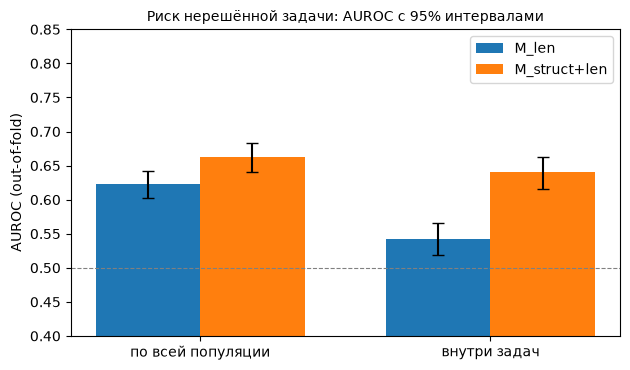

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
modes = [("AUROC", boot, "по всей популяции"), ("AUROC within tasks", wboot, "внутри задач")]
w = 0.36
for j, name in enumerate(MODELS):
    vals = [results.loc[name, m] for m, _, _ in modes]
    errs = np.array([[results.loc[name, m] - ci(b[name])[0], ci(b[name])[1] - results.loc[name, m]]
                     for m, b, _ in modes]).T
    ax.bar(np.arange(2) + (j - 0.5) * w, vals, w, yerr=errs, capsize=4, label=name)
ax.axhline(0.5, color="grey", lw=0.8, ls="--")
ax.set_xticks(np.arange(2), [lbl for _, _, lbl in modes])
ax.set_ylim(0.4, 0.85)
ax.set_ylabel("AUROC (out-of-fold)")
ax.set_title("Риск нерешённой задачи: AUROC с 95% интервалами", fontsize=10)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Практическая полезность

Если проверять вручную только самые подозрительные прогоны: бюджет k — доля популяции с наибольшим риском.
precision@k — доля нерешённых среди отобранных, lift@k — во сколько раз она выше, чем при случайном выборе.

In [13]:
util = []
base = y.mean()
for frac in (0.05, 0.10, 0.20):
    k = math.ceil(frac * len(pop))
    for name in MODELS:
        top = np.argsort(-risk[name], kind="mergesort")[:k]
        p = y[top].mean()
        util.append({"budget": f"{frac:.0%}", "checked": k, "model": name, "unresolved found": int(y[top].sum()),
                     "precision@k": round(p, 3), "lift@k": round(p / base, 2)})
utility = pd.DataFrame(util).set_index(["budget", "checked", "model"])
print(f"base rate of unresolved runs: {base:.3f}")
display(utility)

base rate of unresolved runs: 0.330


unresolved found  precision@k  lift@k
budget checked model                                              
5%     394     M_len                      254        0.645    1.95
               M_struct+len               285        0.723    2.19
10%    787     M_len                      437        0.555    1.68
               M_struct+len               497        0.632    1.91
20%    1573    M_len                      777        0.494    1.50
               M_struct+len               835        0.531    1.61

## 8. Ранжирование

Десять прогонов с наибольшим риском `M_struct+len` (out-of-fold: модель не видела задачу прогона при обучении).

In [14]:
top10 = pop.assign(risk=risk["M_struct+len"]).nlargest(10, "risk")[["task_id", "model", "n_steps", "risk",
                                                                     "resolved"]]
display(top10.round(3))

,task_id,model,n_steps,risk,resolved
2930,sympy__sympy-16766,glm-4.6,6,0.990,0
2737,matplotlib__matplotlib-21568,glm-4.6,244,0.985,0
2014,django__django-10097,minimax-m2,52,0.984,1
3056,django__django-12663,devstral-2512,2,0.972,0
3735,pydata__xarray-6599,devstral-small-2512,155,0.965,0
622,django__django-13741,GLM-4.5,2,0.962,0
2492,astropy__astropy-14598,glm-4.6,222,0.952,0
2421,sympy__sympy-13878,minimax-m2,236,0.948,1
2903,sympy__sympy-12489,glm-4.6,170,0.945,0
2915,sympy__sympy-13878,glm-4.6,176,0.942,0


## 9. Оценка одной траектории

`score_trajectory` получает только шаги прогона, сама размечает фазы по командам, считает признаки и возвращает риск.
Модель для каждого примера обучается на популяции **без задачи этого примера**, так что задача в обучении не
встречалась. Пример «обрыв без отправки» лежит вне популяции — его риск показан только для иллюстрации.

In [15]:
_models = {}


def score_trajectory(steps_df):
    """Risk that the submitted result does not pass the hidden tests, from the steps of one run."""
    run_id = steps_df.run_id.iloc[0]
    task = runs_by_id.loc[run_id, "task_id"]
    if task not in _models:  # demo model trained on every task except this one
        train = pop[pop.task_id != task]
        _models[task] = new_model().fit(train[FEATURES].to_numpy(float), 1 - train.resolved.to_numpy())
    f = trajectory_features(steps_from_frame(steps_df))  # phases are relabelled from the commands here
    x = np.array([[f[c] for c in FEATURES]], dtype=float)
    return float(_models[task].predict_proba(x)[0, 1])


scored = []
for e in examples:
    s = steps[steps.run_id == e["run_id"]]
    r = runs_by_id.loc[e["run_id"]]
    assert r.task_id not in set(pop[pop.task_id != r.task_id].task_id)
    scored.append({"example": TYPE_NAMES[e["type"]], "task_id": r.task_id, "model": r.model,
                   "submitted": int(r.submitted), "risk": round(score_trajectory(s), 3), "resolved": int(r.resolved)})
display(pd.DataFrame(scored))

,example,task_id,model,submitted,risk,resolved
0,пара внутри задачи: решено,django__django-11333,kimi-k2.5@high,1,0.235,1
1,пара внутри задачи: не решено,django__django-11333,GLM-4.5,1,0.413,0
2,ложное заявление об успехе,psf__requests-1766,minimax-m2,1,0.250,0
3,достоверное выполнение с проверкой,django__django-11066,devstral-2512,1,0.187,1
4,обрыв без отправки,django__django-14011,gemini-3-pro-preview@high,0,0.363,0


## 10. Ограничения

1. Только SWE-bench Verified и один каркас агента (mini-SWE-agent, режим bash-only); перенос на другие домены
   отдельно проверялся в работе и не подтвердился.
2. Метка — скрытые тесты бенчмарка: «решено» значит «прошли тесты SWE-bench», а не ручная проверка правильности.
3. `claim_success` — детектор на регулярных выражениях (G0); заявления, сформулированные иначе, он пропускает.
4. Признаки могут частично отражать идентичность модели (её манеру работы), а не только качество конкретного прогона.
5. Числа отличаются от прежних: в E5 модель обучалась на подвыборке 2877 траекторий с заявлением об успехе, здесь —
   на всех отправленных прогонах, и AUROC считается по объединённым out-of-fold предсказаниям.

In [16]:
summary = {"population": len(pop), "excluded": int(len(excluded)),
           "auroc": {m: float(auroc(y, risk[m])) for m in MODELS},
           "auroc_ci": {m: [float(v) for v in ci(boot[m])] for m in MODELS},
           "auroc_diff": [float(d), float(dlo), float(dhi)],
           "within": {m: float(within[m]) for m in MODELS},
           "within_ci": {m: [float(v) for v in ci(wboot[m])] for m in MODELS},
           "within_diff": [float(wd), float(wdlo), float(wdhi)],
           "within_tasks": len(pair_tasks), "within_pairs": n_pairs,
           "fold_avg": {m: float(results.loc[m, "fold-averaged AUROC (check)"]) for m in MODELS},
           "utility": utility.reset_index().to_dict("records"), "scored": scored,
           "elapsed_s": round(time.time() - T0, 1)}
Path("demo_results.json").write_text(json.dumps(summary, indent=1, ensure_ascii=False,
                                                default=lambda o: o.item() if hasattr(o, "item") else str(o)),
                                     encoding="utf-8")
print(f"done in {time.time() - T0:.0f} s (after pip install)")

done in 10 s (after pip install)
